In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Enable a GPU under Runtime → Change runtime type.")



PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
!pip -q install kaggle

In [ ]:
import os
from getpass import getpass
from pathlib import Path

token = getpass("Paste your NEW Kaggle API token: ").strip()

os.environ["KAGGLE_API_TOKEN"] = token

print("Token loaded for this Colab session.")

Paste your NEW Kaggle API token: ··········
Token loaded for this Colab session.


In [ ]:

import os
import subprocess
from pathlib import Path

DATA_DIR = Path("/content/deepfake_dataset")
DATA_DIR.mkdir(parents=True, exist_ok=True)

env = os.environ.copy()

# Use the token securely without printing it.
result = subprocess.run(
    [
        "kaggle", "datasets", "download",
        "-d", "manjilkarki/deepfake-and-real-images",
        "-p", str(DATA_DIR)
    ],
    env=env,
    text=True,
    capture_output=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(
        "Download failed. Check Kaggle authentication and dataset access."
    )

print("Download command completed.")
print("Downloaded files:", list(DATA_DIR.iterdir()))


Dataset URL: https://www.kaggle.com/datasets/manjilkarki/deepfake-and-real-images
License(s): unknown


Download command completed.
Downloaded files: [PosixPath('/content/deepfake_dataset/deepfake-and-real-images.zip')]


In [ ]:

from pathlib import Path
import zipfile

ZIP_PATH = Path(
    "/content/deepfake_dataset/deepfake-and-real-images.zip"
)
EXTRACT_DIR = Path("/content/deepfake_dataset/extracted")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

if not ZIP_PATH.exists():
    raise FileNotFoundError(f"ZIP not found: {ZIP_PATH}")

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()

    if bad_file:
        raise RuntimeError(f"Corrupt file found in ZIP: {bad_file}")

    print(f"Extracting {len(archive.infolist()):,} archive entries...")
    archive.extractall(EXTRACT_DIR)

print("\nExtraction complete.")
print("Top-level contents:")
for path in EXTRACT_DIR.iterdir():
    print(path.name, "—", "folder" if path.is_dir() else "file")


Extracting 190,335 archive entries...

Extraction complete.
Top-level contents:
Dataset — folder


In [ ]:

from pathlib import Path

EXTRACT_DIR = Path("/content/deepfake_dataset/extracted")

if not EXTRACT_DIR.exists():
    raise FileNotFoundError(
        "Extracted folder not found. Run the extraction cell first."
    )

print("Extracted dataset contents:")
for path in sorted(EXTRACT_DIR.iterdir()):
    print(f"  {path.name}/" if path.is_dir() else f"  {path.name}")

print("\nSearching for split folders...")
for split in ["Train", "Validation", "Test", "Valid"]:
    matches = list(EXTRACT_DIR.rglob(split))
    for folder in matches:
        if folder.is_dir():
            print(f"\n{split}: {folder}")
            for class_dir in sorted(folder.iterdir()):
                if class_dir.is_dir():
                    count = sum(
                        1 for p in class_dir.rglob("*")
                        if p.is_file() and p.suffix.lower() in {
                            ".jpg", ".jpeg", ".png", ".webp", ".bmp"
                        }
                    )
                    print(f"  {class_dir.name}: {count:,} images")


Extracted dataset contents:
  Dataset/

Searching for split folders...

Train: /content/deepfake_dataset/extracted/Dataset/Train
  Fake: 70,001 images
  Real: 70,001 images

Validation: /content/deepfake_dataset/extracted/Dataset/Validation
  Fake: 19,641 images
  Real: 19,787 images

Test: /content/deepfake_dataset/extracted/Dataset/Test
  Fake: 5,492 images
  Real: 5,413 images


In [ ]:
import time
import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
class BasicCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = BasicCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)

BasicCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [ ]:
DATA_DIR = Path("/content/deepfake_dataset/extracted/Dataset")

IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(
    DATA_DIR / "Train", transform=train_transform
)
val_dataset = datasets.ImageFolder(
    DATA_DIR / "Validation", transform=eval_transform
)
test_dataset = datasets.ImageFolder(
    DATA_DIR / "Test", transform=eval_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True
)

print("Class mapping:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Class mapping: {'Fake': 0, 'Real': 1}
Training images: 140002
Validation images: 39428
Test images: 10905


In [ ]:

epochs = 10
best_loss = 0.3500
best_loss = float("inf")

train_losses = []
val_losses = []
train_accs = []
val_accs = []

for epoch in range(5, epochs):
    # Training
    model.train()
    loss_sum = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = loss_sum / total
    train_acc = correct / total

    # Validation
    model.eval()
    loss_sum = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss_sum += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    val_loss = loss_sum / total
    val_acc = correct / total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    # Save best model
    if val_loss < best_loss:
        best_loss = val_loss
        torch.save(model.state_dict(), "/content/basic_cnn_best.pth")

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

# Load the best model
model.load_state_dict(torch.load("/content/basic_cnn_best.pth", map_location=device))

print("Training complete!")


Epoch [6/10] | Train Loss: 0.2602 | Train Acc: 0.8922 | Val Loss: 0.3380 | Val Acc: 0.8563
Epoch [7/10] | Train Loss: 0.2391 | Train Acc: 0.9022 | Val Loss: 0.3741 | Val Acc: 0.8475
Epoch [8/10] | Train Loss: 0.2243 | Train Acc: 0.9087 | Val Loss: 0.3124 | Val Acc: 0.8638
Epoch [9/10] | Train Loss: 0.2135 | Train Acc: 0.9131 | Val Loss: 0.2919 | Val Acc: 0.8764
Epoch [10/10] | Train Loss: 0.2032 | Train Acc: 0.9187 | Val Loss: 0.3265 | Val Acc: 0.8668
Training complete!


In [ ]:
model.load_state_dict(
    torch.load("/content/basic_cnn_best.pth", map_location=device)
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Best saved model loaded.")


Best saved model loaded.


In [ ]:
import os

print("Checkpoint exists:", os.path.exists("/content/basic_cnn_best.pth"))

Checkpoint exists: True


In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import torch

# Load the best saved model
model.load_state_dict(
    torch.load("/content/basic_cnn_best.pth", map_location=device)
)
model.eval()

actual = []
predicted = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        actual.extend(labels.numpy())
        predicted.extend(preds.cpu().numpy())

fake = test_dataset.class_to_idx["Fake"]

print(f"Test Accuracy:  {accuracy_score(actual, predicted):.4f}")
print(f"Fake Precision: {precision_score(actual, predicted, pos_label=fake, zero_division=0):.4f}")
print(f"Fake Recall:    {recall_score(actual, predicted, pos_label=fake, zero_division=0):.4f}")
print(f"Fake F1-score:  {f1_score(actual, predicted, pos_label=fake, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    actual, predicted,
    labels=[test_dataset.class_to_idx["Fake"],
            test_dataset.class_to_idx["Real"]],
    target_names=["Fake", "Real"],
    zero_division=0
))

print("Confusion Matrix (rows = actual, columns = predicted):")
print(confusion_matrix(
    actual, predicted,
    labels=[test_dataset.class_to_idx["Fake"],
            test_dataset.class_to_idx["Real"]]
))



Test Accuracy:  0.7945
Fake Precision: 0.7588
Fake Recall:    0.8678
Fake F1-score:  0.8096

Classification Report:
              precision    recall  f1-score   support

        Fake       0.76      0.87      0.81      5492
        Real       0.84      0.72      0.78      5413

    accuracy                           0.79     10905
   macro avg       0.80      0.79      0.79     10905
weighted avg       0.80      0.79      0.79     10905

Confusion Matrix (rows = actual, columns = predicted):
[[4766  726]
 [1515 3898]]


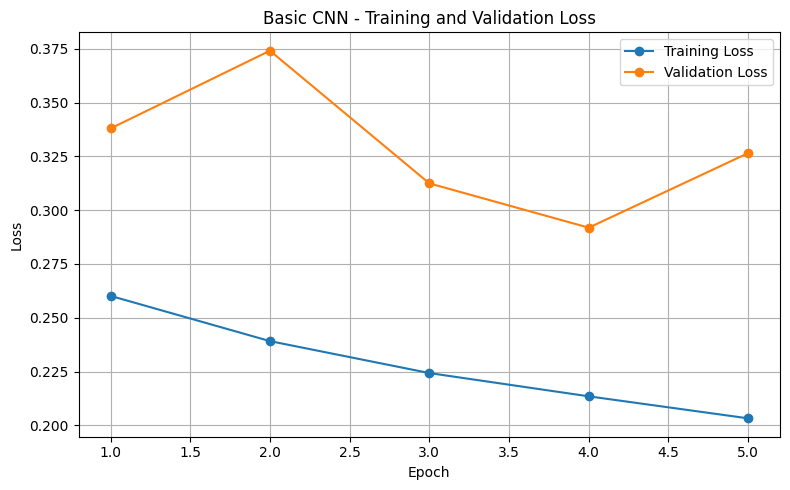

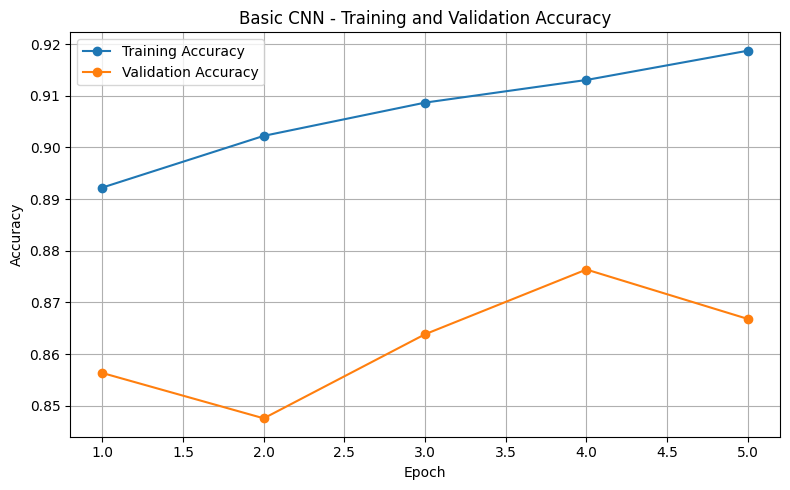

In [ ]:

import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Basic CNN - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/basic_cnn_loss.png", dpi=150)
plt.show()

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accs, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accs, marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Basic CNN - Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/basic_cnn_accuracy.png", dpi=150)
plt.show()


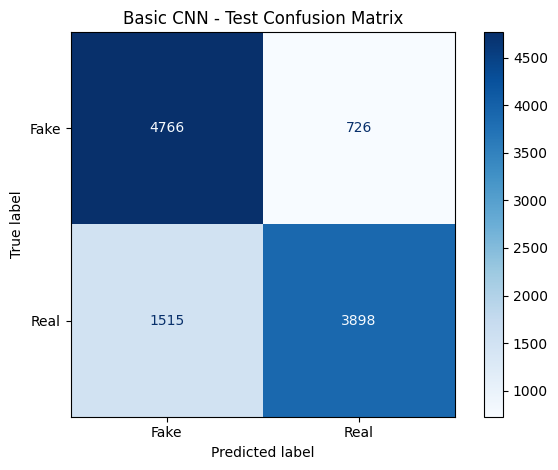

In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    actual,
    predicted,
    labels=[
        test_dataset.class_to_idx["Fake"],
        test_dataset.class_to_idx["Real"]
    ]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake", "Real"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Basic CNN - Test Confusion Matrix")
plt.tight_layout()
plt.savefig("/content/basic_cnn_confusion_matrix.png", dpi=150)
plt.show()


In [ ]:

import json
import shutil
from pathlib import Path
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

results_dir = Path("/content/basic_cnn_results")
results_dir.mkdir(exist_ok=True)

# Save model weights
torch.save(model.state_dict(), results_dir / "basic_cnn_best.pth")

# Save measured test metrics
fake = test_dataset.class_to_idx["Fake"]

metrics = {
    "test_accuracy": accuracy_score(actual, predicted),
    "fake_precision": precision_score(
        actual, predicted, pos_label=fake, zero_division=0
    ),
    "fake_recall": recall_score(
        actual, predicted, pos_label=fake, zero_division=0
    ),
    "fake_f1": f1_score(
        actual, predicted, pos_label=fake, zero_division=0
    )
}

with open(results_dir / "test_metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)

# Save epoch history
pd.DataFrame({
    "train_loss": train_losses,
    "validation_loss": val_losses,
    "train_accuracy": train_accs,
    "validation_accuracy": val_accs
}).to_csv(results_dir / "training_history.csv", index=False)

# Copy graphs
for name in [
    "basic_cnn_loss.png",
    "basic_cnn_accuracy.png",
    "basic_cnn_confusion_matrix.png"
]:
    path = Path("/content") / name
    if path.exists():
        shutil.copy2(path, results_dir / name)

# Save predictions
pd.DataFrame({
    "actual_label": actual,
    "predicted_label": predicted
}).to_csv(results_dir / "test_predictions.csv", index=False)

zip_path = shutil.make_archive(
    "/content/basic_cnn_results", "zip", results_dir
)

print("Results saved:", zip_path)
print("Test metrics:", metrics)
from google.colab import files
files.download("/content/basic_cnn_results.zip")

Results saved: /content/basic_cnn_results.zip
Test metrics: {'test_accuracy': 0.7944979367262723, 'fake_precision': 0.7587963700047763, 'fake_recall': 0.8678077203204662, 'fake_f1': 0.8096491973158922}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

backup_dir = Path("/content/drive/MyDrive/Deepfake_Project")
backup_dir.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    "/content/basic_cnn_results.zip",
    backup_dir / "basic_cnn_results.zip"
)

print("Backup saved to Google Drive.")

Mounted at /content/drive
Backup saved to Google Drive.


In [ ]:
import json
from pathlib import Path

path = Path("/content/basic_cnn_results/test_metrics.json")

if path.exists():
    with open(path, "r") as f:
        metrics = json.load(f)

    print("Basic CNN Test Results")
    for name, value in metrics.items():
        print(f"{name}: {value:.4f}")
else:
    print("Metrics file not found.")
    print("Run the test evaluation and results-saving cells first.")

Basic CNN Test Results
test_accuracy: 0.7945
fake_precision: 0.7588
fake_recall: 0.8678
fake_f1: 0.8096


In [ ]:
from pathlib import Path
import torch

model_path = Path("/content/basic_cnn_best.pth")
results_path = Path("/content/basic_cnn_results")

print("Best model saved:", model_path.exists())
print("Results folder exists:", results_path.exists())

if results_path.exists():
    print("\nSaved files:")
    for file in sorted(results_path.iterdir()):
        print("-", file.name)

Best model saved: True
Results folder exists: True

Saved files:
- basic_cnn_accuracy.png
- basic_cnn_best.pth
- basic_cnn_confusion_matrix.png
- basic_cnn_loss.png
- test_metrics.json
- test_predictions.csv
- training_history.csv


In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

source = Path("/content/basic_cnn_results")
destination = Path("/content/drive/MyDrive/Deepfake_Project")

destination.mkdir(parents=True, exist_ok=True)

if not source.exists():
    raise FileNotFoundError(
        "Results folder not found. Run the results-saving cell first."
    )

shutil.copytree(
    source,
    destination / "basic_cnn_results",
    dirs_exist_ok=True
)

model = Path("/content/basic_cnn_best.pth")
if model.exists():
    shutil.copy2(model, destination / "basic_cnn_best.pth")

print("Backup completed.")
print("Location:", destination)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backup completed.
Location: /content/drive/MyDrive/Deepfake_Project


In [ ]:

import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class BasicCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = BasicCNN().to(device)

model.load_state_dict(
    torch.load("/content/basic_cnn_best.pth", map_location=device)
)

model.eval()

print("Best saved model loaded successfully.")


Best saved model loaded successfully.


In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, confusion_matrix
)

actual = []
predicted = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        actual.extend(labels.numpy().tolist())
        predicted.extend(preds.cpu().numpy().tolist())

fake = test_dataset.class_to_idx["Fake"]

print(f"Test Accuracy:  {accuracy_score(actual, predicted):.4f}")
print(f"Fake Precision: {precision_score(actual, predicted, pos_label=fake, zero_division=0):.4f}")
print(f"Fake Recall:    {recall_score(actual, predicted, pos_label=fake, zero_division=0):.4f}")
print(f"Fake F1-score:  {f1_score(actual, predicted, pos_label=fake, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    actual,
    predicted,
    labels=[
        test_dataset.class_to_idx["Fake"],
        test_dataset.class_to_idx["Real"]
    ],
    target_names=["Fake", "Real"],
    zero_division=0
))

print("Confusion Matrix (rows = actual, columns = predicted):")
print(confusion_matrix(
    actual,
    predicted,
    labels=[
        test_dataset.class_to_idx["Fake"],
        test_dataset.class_to_idx["Real"]
    ]
))

Test Accuracy:  0.7945
Fake Precision: 0.7588
Fake Recall:    0.8678
Fake F1-score:  0.8096

Classification Report:
              precision    recall  f1-score   support

        Fake       0.76      0.87      0.81      5492
        Real       0.84      0.72      0.78      5413

    accuracy                           0.79     10905
   macro avg       0.80      0.79      0.79     10905
weighted avg       0.80      0.79      0.79     10905

Confusion Matrix (rows = actual, columns = predicted):
[[4766  726]
 [1515 3898]]


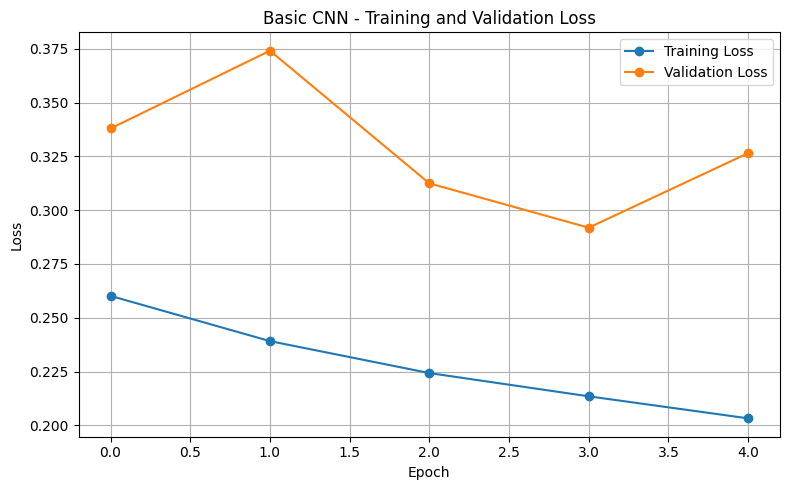

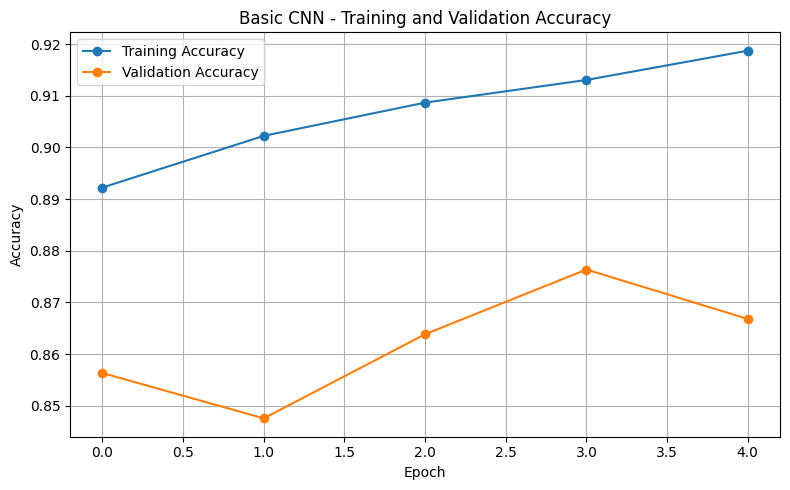

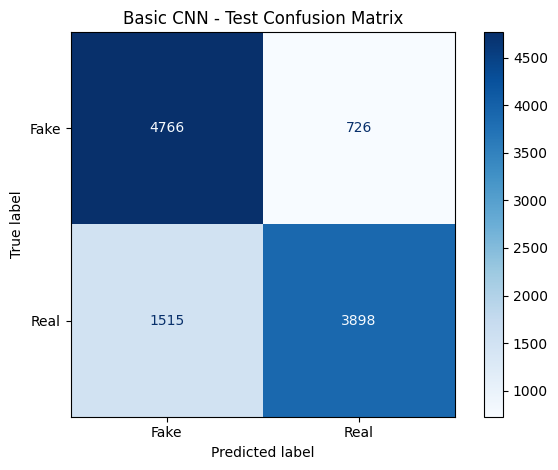

Graphs saved in: /content/basic_cnn_results


In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from pathlib import Path

out = Path("/content/basic_cnn_results")
out.mkdir(exist_ok=True)

# Training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training Loss", marker="o")
plt.plot(val_losses, label="Validation Loss", marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Basic CNN - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(out / "loss.png", dpi=150)
plt.show()

# Training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(train_accs, label="Training Accuracy", marker="o")
plt.plot(val_accs, label="Validation Accuracy", marker="o")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Basic CNN - Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(out / "accuracy.png", dpi=150)
plt.show()

# Test confusion matrix
cm = confusion_matrix(
    actual,
    predicted,
    labels=[
        test_dataset.class_to_idx["Fake"],
        test_dataset.class_to_idx["Real"]
    ]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake", "Real"]
).plot(cmap="Blues", values_format="d")

plt.title("Basic CNN - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(out / "confusion_matrix.png", dpi=150)
plt.show()

print("Graphs saved in:", out)


In [ ]:

import json
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

torch.save(model.state_dict(), out / "basic_cnn_best.pth")

fake = test_dataset.class_to_idx["Fake"]

metrics = {
    "test_accuracy": accuracy_score(actual, predicted),
    "fake_precision": precision_score(
        actual, predicted, pos_label=fake, zero_division=0
    ),
    "fake_recall": recall_score(
        actual, predicted, pos_label=fake, zero_division=0
    ),
    "fake_f1": f1_score(
        actual, predicted, pos_label=fake, zero_division=0
    )
}

with open(out / "test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

pd.DataFrame({
    "train_loss": train_losses,
    "validation_loss": val_losses,
    "train_accuracy": train_accs,
    "validation_accuracy": val_accs
}).to_csv(out / "training_history.csv", index=False)

pd.DataFrame({
    "actual": actual,
    "predicted": predicted
}).to_csv(out / "test_predictions.csv", index=False)

print("Model, metrics, history, and predictions saved.")
print(metrics)


Model, metrics, history, and predictions saved.
{'test_accuracy': 0.7944979367262723, 'fake_precision': 0.7587963700047763, 'fake_recall': 0.8678077203204662, 'fake_f1': 0.8096491973158922}


In [ ]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/basic_cnn_results",
    "zip",
    root_dir="/content/basic_cnn_results"
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>